In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

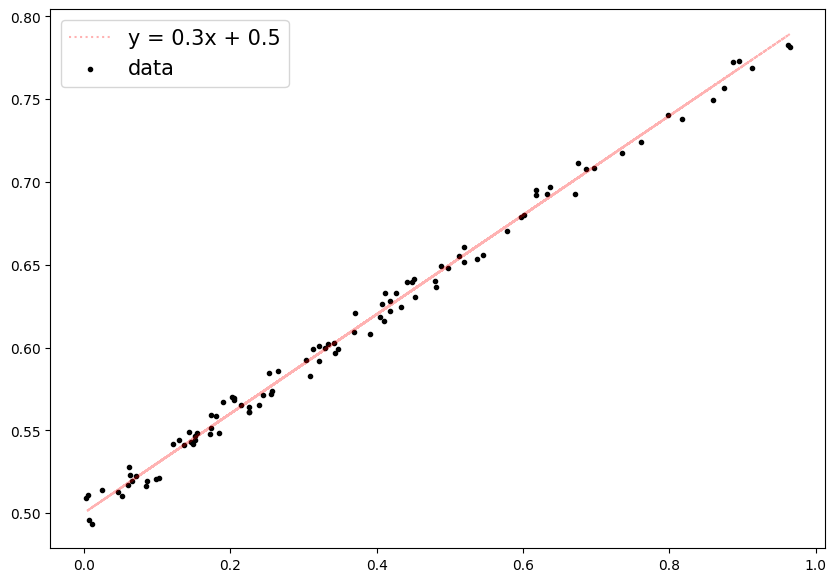

w: 0.3, b: 0.5


In [ ]:
def make_linear(w=0.5, b=0.8, size=50, noise=1.0):
    x = np.random.rand(size)
    y = w * x + b
    noise = np.random.uniform(-abs(noise), abs(noise), size=y.shape)
    yy = y + noise
    plt.figure(figsize=(10, 7))
    plt.plot(x, y, color='r', label=f'y = {w}x + {b}', linestyle=':', alpha=0.3)
    plt.scatter(x, yy, color='black', label='data', marker='.')
    plt.legend(fontsize=15)
    plt.show()
    print(f'w: {w}, b: {b}')
    return x, yy

x, y = make_linear(w=0.3, b=0.5, size=100, noise=0.01)

In [ ]:
x = torch.tensor(x)
y = torch.tensor(y)
print(type(x))

<class 'torch.Tensor'>


In [ ]:
w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

In [ ]:
y_hat = w*x + b

In [ ]:
loss = ((y - y_hat)**2).mean()

In [ ]:
loss.backward()

In [ ]:
print(f'w grad: {w.grad.item():.3f}, b grad: {b.grad.item():.3f}')

w grad: -2.189, b grad: -5.387


경사하강법(Gradient Descent)

In [ ]:
epochs = 500
lr = 0.1

In [ ]:
# weight & bias initialization
w = torch.randn(1)
b = torch.randn(1)

w.requires_grad = True
b.requires_grad = True

In [ ]:
losses = []
ws = []
bs = []

for e in range(epochs):
    y_hat = w*x + b
    loss = ((y - y_hat)**2).mean()
    loss.backward()

    # w.grad(b.grad)가 None이 되는 것을 방지
    with torch.no_grad():
        w -= lr*w.grad
        b -= lr*b.grad

        # 그라디언트 초기화(epoch 마다 backward()를 부를 때마다 gradient 값이 계속 누적됨)
        w.grad.zero_()
        b.grad.zero_()

    losses.append(loss.item())
    ws.append(w.item())
    bs.append(b.item())

    if e % 5 == 0:
        print(f'epoch = {e}, w = {w.item():.3f}, b = {b.item():.3f}, loss = {loss.item():.3f}')

epoch = 0, w = 2.145, b = 0.397, loss = 0.808
epoch = 5, w = 1.905, b = 0.043, loss = 0.204
epoch = 10, w = 1.780, b = -0.031, loss = 0.143
epoch = 15, w = 1.689, b = -0.029, loss = 0.125
epoch = 20, w = 1.611, b = -0.008, loss = 0.112
epoch = 25, w = 1.540, b = 0.018, loss = 0.100
epoch = 30, w = 1.472, b = 0.043, loss = 0.090
epoch = 35, w = 1.409, b = 0.068, loss = 0.080
epoch = 40, w = 1.349, b = 0.091, loss = 0.072
epoch = 45, w = 1.292, b = 0.113, loss = 0.064
epoch = 50, w = 1.238, b = 0.134, loss = 0.058
epoch = 55, w = 1.187, b = 0.154, loss = 0.052
epoch = 60, w = 1.139, b = 0.173, loss = 0.046
epoch = 65, w = 1.094, b = 0.190, loss = 0.041
epoch = 70, w = 1.051, b = 0.207, loss = 0.037
epoch = 75, w = 1.010, b = 0.223, loss = 0.033
epoch = 80, w = 0.972, b = 0.238, loss = 0.030
epoch = 85, w = 0.935, b = 0.252, loss = 0.026
epoch = 90, w = 0.901, b = 0.266, loss = 0.024
epoch = 95, w = 0.868, b = 0.278, loss = 0.021
epoch = 100, w = 0.837, b = 0.290, loss = 0.019
epoch = 105

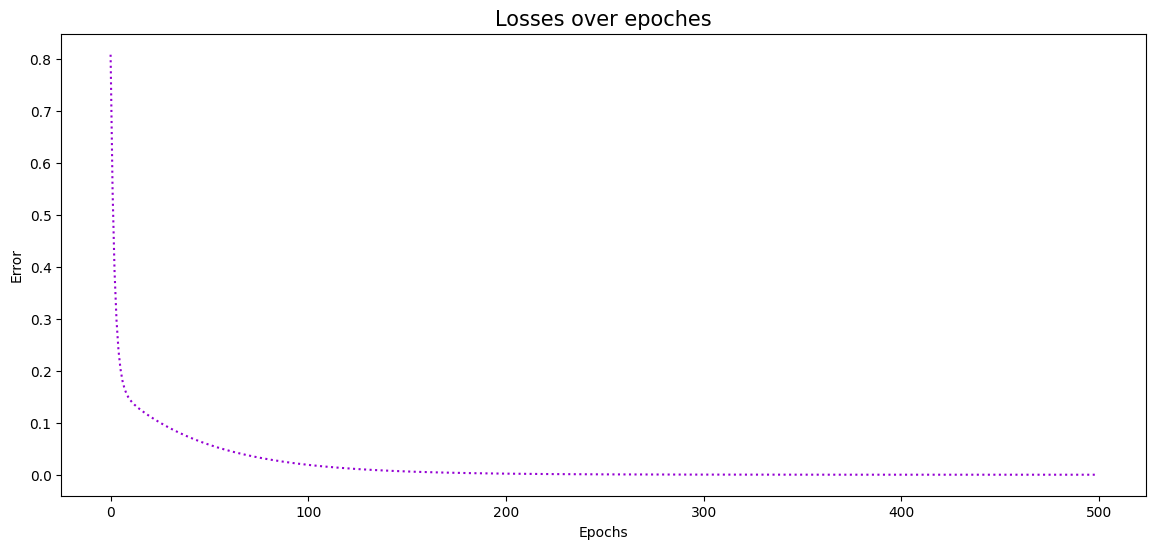

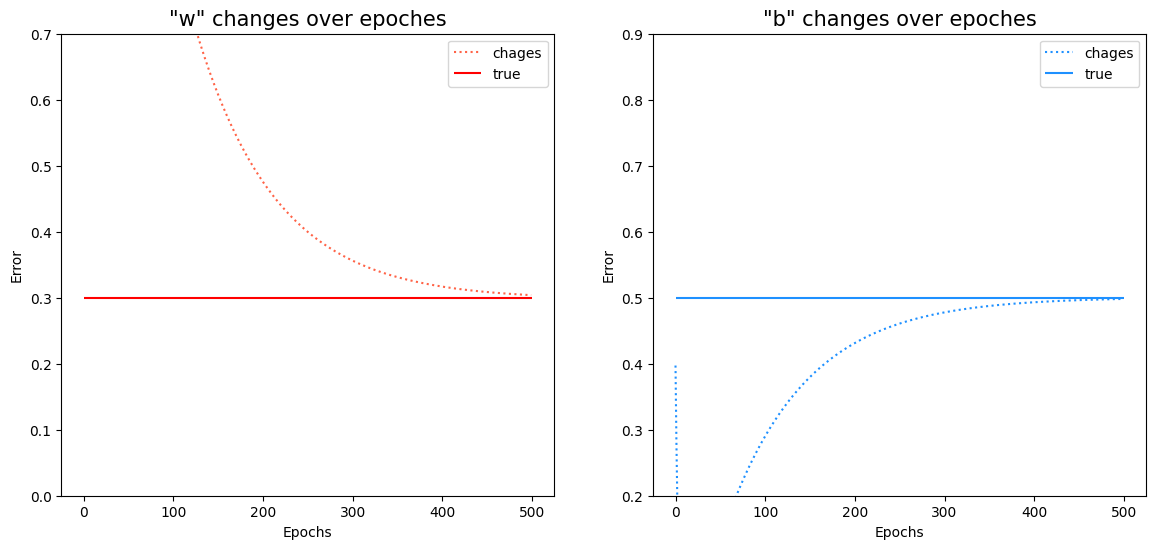

In [ ]:
# 전체 loss 에 대한 변화량 시각화
plt.figure(figsize=(14, 6))
plt.plot(losses, c='darkviolet', linestyle=':')

plt.title('Losses over epoches', fontsize=15)
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()

# w, b에 대한 변화량 시각화
fig, axes = plt.subplots(1, 2)
fig.set_size_inches(14, 6)

axes[0].plot(ws, c='tomato', linestyle=':', label='chages')
axes[0].hlines(y=0.3, xmin=0, xmax=len(ws), color='r', label='true')
axes[0].set_ylim(0, 0.7)
axes[0].set_title('"w" changes over epoches', fontsize=15)
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Error')
axes[0].legend()

axes[1].plot(bs, c='dodgerblue', linestyle=':', label='chages')
axes[1].hlines(y=0.5, xmin=0, xmax=len(ws), color='dodgerblue', label='true')
axes[1].set_ylim(0.2, 0.9)
axes[1].set_title('"b" changes over epoches', fontsize=15)
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Error')
axes[1].legend()

plt.show()